# Stabilität: wächst eine kleine Störung, oder stirbt sie ab?

Ob ein System vorhersagbar bleibt, seinen Anfang vergisst oder sich an ihn erinnert, entscheidet eine einzige Frage: Was geschieht mit einer kleinen Störung? Das Notebook stellt sie an acht Systemen: der logistischen Abbildung und dem Lorenz-System, Sternbahnen in einer Galaxie und den Lücken im Asteroidengürtel (Daten des JPL), der Ausbreitung einer Störung in einer Quantenkette (OTOC), der Thermalisierung und ihrem Gegenteil, der Vielteilchen-Lokalisierung, der Synchronisation vieler Oszillatoren, dem Ausfrieren der Neutronen kurz nach dem Urknall, Regelkreisen von der adaptiven Optik bis zum Gradientenabstieg und einer Raumsonde am instabilen Punkt L2, deren besten Regler die Optimal Control berechnet und ein Agent ohne Modell lernt. Der Code steht in [`code/stability/`](https://github.com/deltorobarba/science/tree/main/code/stability) (`chaos.py` für Lyapunov-Exponenten, Sternbahnen und Asteroiden, `scrambling.py` für die Quantenketten, `collective.py` für die Synchronisation, `freezeout.py` für das frühe Universum, `feedback.py` für die Regelkreise, `control.py` für Optimal Control und Q-Learning); hier stehen nur die Auswahl, die Aufrufe und die Bilder.

**Der rote Faden**

Die anderen fünf Prinzipien betrachten einen Zustand oder einen Datensatz: wie man ihn knapp beschreibt (`symmetries`, `principal_axes`, `approximation`) und was man über ihn wissen kann (`reconstruction`, `limits_of_knowledge`). Dieses Notebook fragt, wie sich ein System in der Zeit entwickelt. Alle Schritte beantworten das mit demselben Test: das System ein wenig stören und nachsehen, ob die Störung wächst oder abklingt. Das Vorzeichen eines Eigenwerts oder eines Lyapunov-Exponenten entscheidet.

- **Schritte 1 und 2, Mathematik und Himmelsmechanik:** Chaos heißt, dass ein Anfangsfehler exponentiell wächst. Sternbahnen in einer Galaxie und Asteroiden im Gürtel zeigen, wie Regelmäßigkeit und Chaos nebeneinander liegen.
- **Schritte 3 und 4, Quantenphysik:** Auch Quantensysteme verwürfeln Information (Scrambling) und vergessen ihren Anfang (Thermalisierung), außer starke Unordnung hält sie fest (Lokalisierung).
- **Schritt 5, kollektive Dynamik:** Viele gekoppelte Oszillatoren synchronisieren sich, sobald der ungeordnete Zustand instabil wird. Das ist ein Phasenübergang.
- **Schritt 6, Kosmologie:** Das frühe Universum vergaß jede Abweichung vom Gleichgewicht, solange die Reaktionen schneller waren als die Expansion. Danach erinnerte es sich, und diese Erinnerung messen wir heute als Helium.
- **Schritt 7, Regelung und maschinelles Lernen:** Rückkopplung verschiebt Eigenwerte. Eine adaptive Optik und ein Gradientenabstieg kippen an derselben Grenze.
- **Schritt 8, Optimal Control und Reinforcement Learning:** Rückkopplung kann auch Instabiles stabil machen. Welcher Regler das mit dem wenigsten Treibstoff tut, folgt aus der Riccati-Gleichung, und ein Agent findet denselben Regler ohne Modell.

Die gemeinsame Lehre: Ob ein System vorhersagbar ist, vergisst oder sich erinnert, entscheidet eine Zahl mit Vorzeichen, der größte Eigenwert der linearisierten Dynamik. Wer sie kennt, weiß, wie lange eine Vorhersage hält, ob ein Regelkreis stabil ist, welche Lernrate noch geht und was es kostet, das Vorzeichen umzudrehen.

**Einführung: Stabilität ist das Vorzeichen eines Eigenwerts**

Ein kleines Beispiel zuerst: eine Population, die wächst, bis sie an eine Grenze stößt (logistisches Wachstum, Kapazität 1),

$$\dot x = f(x) = x\,(1 - x).$$

Sie hat zwei Gleichgewichte, $x^\ast = 0$ und $x^\ast = 1$. Ob ein Gleichgewicht hält, zeigt eine kleine Störung $\delta = x - x^\ast$: Nach Taylor ist $\dot\delta \approx f'(x^\ast)\,\delta$, also $\delta(t) = \delta_0\,e^{f'(x^\ast)\,t}$. Mit $f'(x) = 1 - 2x$ ist $f'(0) = +1$: Eine winzige Population wächst, das Gleichgewicht 0 ist instabil. Bei $x^\ast = 1$ ist $f'(1) = -1$: Jede Abweichung klingt wie $e^{-t}$ ab. Zum Nachrechnen: Start bei $x = 0.9$, also $\delta_0 = -0.1$. Die lineare Näherung sagt nach $t = 1$ eine Abweichung von $0.1\,e^{-1} = 0.037$ voraus; die exakte Lösung $x(t) = 1/\big(1 + (1/x_0 - 1)\,e^{-t}\big)$ gibt $x(1) = 0.961$, also 0.039.

Allgemein hat ein System $\dot{\mathbf x} = \mathbf f(\mathbf x)$ an einem Gleichgewicht die Jacobi-Matrix $J_{ij} = \partial f_i/\partial x_j$, und eine Störung zerfällt in ihre Eigenvektoren: $\boldsymbol\delta(t) = \sum_i c_i\,\mathbf v_i\,e^{\lambda_i t}$. Stabil ist das Gleichgewicht, wenn alle $\mathrm{Re}\,\lambda_i < 0$ sind; bei Schritten statt kontinuierlicher Zeit, $\mathbf x_{k+1} = F(\mathbf x_k)$, müssen alle Eigenwerte im Einheitskreis liegen. Läuft das System nicht in ein Gleichgewicht, sondern auf einer Bahn weiter, misst der Lyapunov-Exponent

$$\lambda = \lim_{t\to\infty} \frac1t \ln\frac{|\boldsymbol\delta(t)|}{|\boldsymbol\delta_0|}$$

das mittlere Wachstum. Drei Fälle ziehen sich durch das Notebook:

- **λ > 0, die Störung wächst:** Chaos oder Instabilität. Eine Vorhersage hält nur etwa $\ln(\Delta/\delta_0)/\lambda$ lang, bis der Anfangsfehler $\delta_0$ die Toleranz $\Delta$ erreicht.
- **λ < 0, die Störung klingt ab:** Das System vergisst seinen Anfang in der Zeit $1/|\lambda|$; so entsteht Gleichgewicht.
- **λ = 0, der kritische Punkt:** Hier wechselt das Verhalten (Bifurkation, Phasenübergang), und alles wird langsam.

| Gebiet (Schritt) | was gestört wird | Kriterium | Ergebnis im Lauf |
|---|---|---|---|
| Mathematik (1) | Anfangswert einer Folge, einer Bahn | Lyapunov-Exponent | Chaos ab $r = 3.570$; Lorenz $\lambda = 0.91$: 1000-mal genauer messen bringt 7 Zeiteinheiten |
| Himmelsmechanik (2) | Sternbahn, Asteroidenbahn | Lyapunov-Exponent, Resonanz | Sternbahnen 0 %, 60 %, 97 % chaotisch; in der 3:1-Lücke 132 statt 4520 Asteroiden |
| Quantenphysik (3) | ein Spin am Rand einer Kette | Front des OTOC | Front mit 1.7 Plätzen je Zeiteinheit; dahinter $C = 0.89$ chaotisch, 0.35 integrabel |
| Quantenphysik (4) | Néel-Muster einer Spinkette | Imbalance, Energieabstände | Imbalance 0.06 bei $W = 0.5$, 0.79 bei $W = 10$; $\langle r\rangle$ von 0.529 auf 0.388 |
| Kollektive Dynamik (5) | ungeordnete Phasen | Eigenwert $K/2 - \gamma$ | Synchronisation ab $K_c = 1$, Theorie auf 0.002 getroffen |
| Kosmologie (6) | Neutronenanteil | Rate $\Gamma$ gegen Expansion $H$ | Ausfrieren bei 0.66 MeV (1.7 s); $Y_p = 0.242$, beobachtet 0.245 |
| Regelung, ML (7) | Phase des Lichts, Gewichte | Faktor je Schritt kleiner als 1 | Regelkreis stabil bis $g = 1$, am besten bei 0.48; Lernrate stabil bis $2/\lambda_{\max} = 0.497$ |
| Raumfahrt, RL (8) | Abstand einer Sonde von L2 | Eigenwerte mit Regler, Kosten | Abweichung ×e alle 23 Tage; LQR hält L2 mit 13 cm/s, Q-Learning trifft ihn auf $10^{-12}$ |

In [1]:
import sys
import urllib.request
from pathlib import Path
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()   # lokal liegt das Notebook in experiments/
CODE = ROOT / "code" / "stability"
if "google.colab" in sys.modules and not CODE.exists():      # in Colab den Code aus dem Repository holen
    CODE.mkdir(parents=True)
    for f in ["chaos.py", "scrambling.py", "collective.py", "freezeout.py", "feedback.py", "control.py"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/stability/{f}", CODE / f)
sys.path.insert(0, str(CODE))      # Ordner direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import chaos, scrambling, collective, freezeout, feedback, control
DATA = Path.cwd() / "data" / "stability"               # Cache für die Asteroiden

**1. Chaos: Ein Anfangsfehler wächst exponentiell**

Die logistische Abbildung $x \to r\,x\,(1 - x)$ ist das einfachste Modell einer Population, die sich von Jahr zu Jahr vermehrt und dabei an Grenzen stößt. Für kleine $r$ landet jede Folge auf einem festen Wert, mit wachsendem $r$ auf einem Zyklus aus 2, 4, 8, … Werten, und ab $r \approx 3.57$ wird sie chaotisch. Der Lyapunov-Exponent $\lambda = \langle \ln|r(1 - 2x)| \rangle$, das mittlere logarithmische Strecken eines kleinen Fehlers je Schritt, zeigt das an (`chaos.plot_logistic_lorenz`). Rechts das Lorenz-System, ein grobes Modell der Konvektion in der Atmosphäre (Lorenz 1963): zwei Bahnen, die sich am Anfang um $10^{-10}$, $10^{-7}$ oder $10^{-4}$ unterscheiden.

**Begriffe**
- **Lyapunov-Exponent:** wie stark ein kleiner Abstand zweier Bahnen im Mittel wächst, $\delta(t) \approx \delta_0\,e^{\lambda t}$; $\lambda > 0$ heißt Chaos.
- **Bifurkation:** ein Wert des Parameters, an dem sich das Verhalten qualitativ ändert; dort ist $\lambda = 0$.
- **Vorhersagehorizont:** etwa $\ln(\Delta/\delta_0)/\lambda$, bis ein Anfangsfehler $\delta_0$ auf die Toleranz $\Delta$ gewachsen ist. Zehnmal genauer messen bringt nur $\ln(10)/\lambda$ mehr Zeit.

Links: Bis $r = 3$ landet die Folge auf einem Wert, dann verdoppelt sich die Periode in immer kürzeren Abständen (2, 4, 8, …), und ab $r \approx 3.570$ wird $\lambda$ positiv, wie von Feigenbaum vorhergesagt (3.5699). Bei $r = 4$ ist $\lambda = 0.693 = \ln 2$: Jeder Schritt verdoppelt einen Fehler im Mittel. Dazwischen liegen Fenster mit Ordnung, etwa die Periode 3 bei $r = 3.83$ mit $\lambda = -0.44$. An jeder Verdopplung berührt $\lambda$ die Null von unten; dort wechselt die Stabilität. Rechts: Der Lyapunov-Exponent des Lorenz-Systems ist 0.91 je Zeiteinheit (Literatur 0.906), ein Fehler wächst also je Zeiteinheit um den Faktor 2.5. Alle drei Anfangsfehler wachsen mit dieser Steigung, bis sie so groß sind wie der Attraktor. Einen Abstand von 1 erreicht der Fehler $10^{-4}$ nach $t = 8.9$, der Fehler $10^{-7}$ nach 15.8 und der Fehler $10^{-10}$ nach 24.0: Tausendmal genauer messen bringt nur etwa 7 Zeiteinheiten mehr Vorhersage ($\ln 1000/0.91 = 7.6$). Deshalb enden Wettervorhersagen nach etwa zwei Wochen, egal wie gut die Messungen werden.

Logistische Abbildung: λ < 0 bis r ≈ 3.570 (Feigenbaum: Chaos ab r = 3.5699); bei r = 4 ist λ = 0.693 (exakt ln 2 = 0.693); bei r = 3.83 (Fenster mit Periode 3) λ = -0.436


Lorenz: größter Lyapunov-Exponent 0.912 pro Zeiteinheit (Literatur 0.906); ein Fehler wächst je Zeiteinheit um den Faktor 2.49


Vorhersagbarkeit: Wann ist der Abstand zweier Bahnen auf 1 gewachsen (Attraktor etwa 40 breit)?


  Anfangsfehler 1e-10: nach t = 24.0 (Schätzung ln(1/δ)/λ = 25.3)


  Anfangsfehler 1e-07: nach t = 15.8 (Schätzung ln(1/δ)/λ = 17.7)


  Anfangsfehler 1e-04: nach t = 8.9 (Schätzung ln(1/δ)/λ = 10.1)


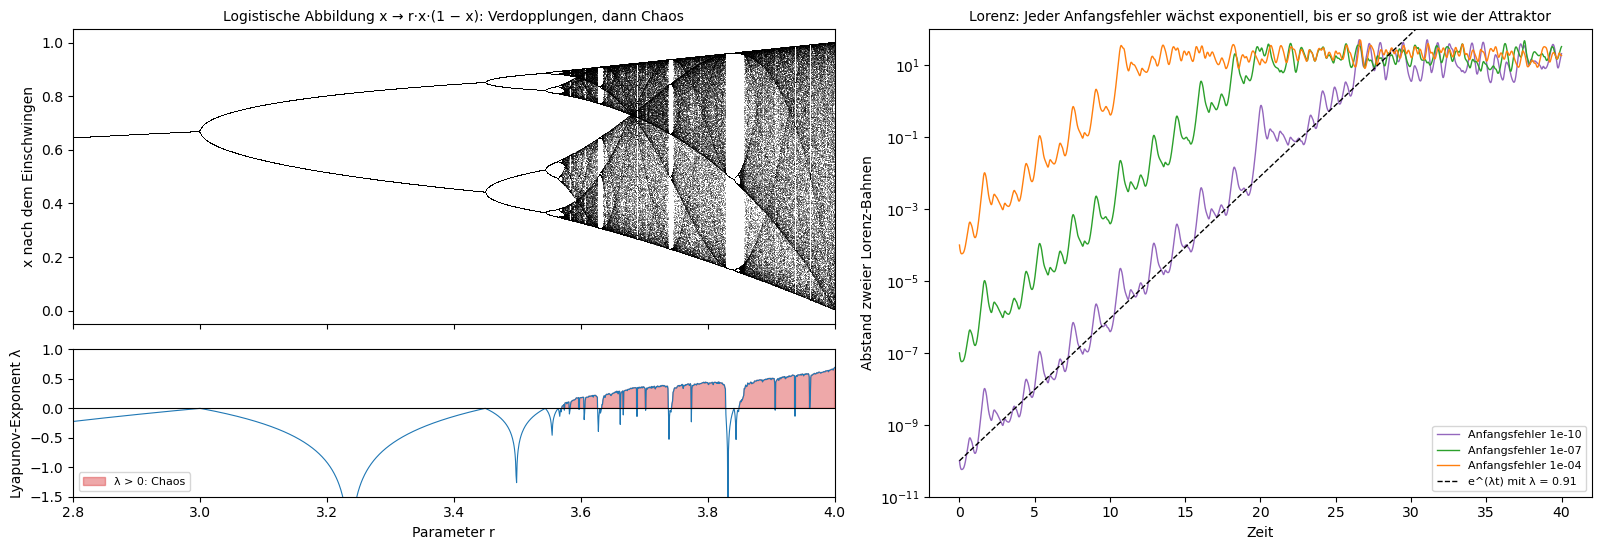

In [2]:
R_RANGE = (2.8, 4.0)               # Bereich des Parameters r
DELTAS = (1e-10, 1e-7, 1e-4)       # Anfangsfehler der Lorenz-Bahnen
lam_lorenz = chaos.plot_logistic_lorenz(*R_RANGE, deltas=DELTAS)

**2. Himmelsmechanik: Sternbahnen in einer Galaxie und Lücken im Asteroidengürtel**

Hénon und Heiles (1964) fragten, ob Sterne in einer Galaxie neben Energie und Drehimpuls eine dritte Erhaltungsgröße haben. Ihr Modellpotential $V = \tfrac12(x^2 + y^2) + x^2 y - y^3/3$ zeigt: bei kleiner Energie ja, die Bahnen sind regelmäßig, bei großer nicht. Für drei Energien werden je 60 Bahnen bis $t = 1000$ integriert, ihr Lyapunov-Exponent berechnet und jede Bahn dort eingezeichnet, wo sie die Ebene $x = 0$ durchstößt (`chaos.henon_heiles`). Rechts echte Daten: die großen Halbachsen von 200 000 nummerierten Asteroiden aus der Small-Body Database des JPL (`chaos.asteroids`). Wo ein Asteroid die Sonne in einem einfachen Verhältnis zu Jupiter umläuft, etwa dreimal pro Jupiterjahr (3:1), addieren sich die Störungen durch Jupiter bei jedem Umlauf (Resonanz).

**Begriffe**
- **Poincaré-Schnitt:** statt der ganzen Bahn nur die Punkte, an denen sie eine Ebene durchstößt. Eine regelmäßige Bahn liegt auf einer geschlossenen Kurve (sie hat eine weitere Erhaltungsgröße), eine chaotische füllt eine Fläche.
- **Energie 1/6:** Bei dieser Energie können Sterne aus dem Potential entkommen; darüber gibt es keine gebundenen Bahnen mehr.
- **Resonanz:** Die Umlaufzeiten stehen im Verhältnis kleiner ganzer Zahlen. Nach Kepler liegt die 3:1-Resonanz bei $a = 5.20\text{ AU} \cdot 3^{-2/3} = 2.50$ AU (1 AU ist der mittlere Abstand Erde–Sonne).

Bei Energie 1/12 sind alle 60 Bahnen regelmäßig: Jede liegt auf einer geschlossenen Kurve, und ihr $\lambda$ bleibt unter 0.006 (in endlicher Rechenzeit ist es nie genau null). Bei 1/8 sind 60 % chaotisch: Ein Meer aus Punkten umgibt Inseln regelmäßiger Bahnen, beides bei derselben Energie. Bei 1/6 sind 97 % chaotisch, mit $\lambda$ bis 0.16. Ob ein Stern regelmäßig läuft, hängt also davon ab, wo er startet, nicht nur von seiner Energie. Rechts die Asteroiden: Bei der 3:1-Resonanz (2.50 AU) liegen 132 Asteroiden in einem Streifen von ±0.01 AU, daneben im Mittel 4520; bei 2:1 (3.28 AU) sind es 24 statt 714, bei 5:2 (2.83 AU) 439 statt 2846. Bahnen in diesen Resonanzen sind chaotisch: Ihre Exzentrizität springt, bis sie die Bahn des Mars kreuzen und durch nahe Begegnungen aus dem Gürtel geworfen werden (Wisdom 1982). Über Jahrmillionen hat das die Lücken leergeräumt, die Kirkwood schon 1866 bemerkt hat. Die schwächere 7:3-Resonanz (2.96 AU) räumt weniger aus, 1330 statt 2024.

Hénon-Heiles, Energie 0.0833: 0% der 60 Bahnen chaotisch (λ > 0.02); größtes λ = 0.006, kleinstes 0.0009


Hénon-Heiles, Energie 0.1250: 60% der 60 Bahnen chaotisch (λ > 0.02); größtes λ = 0.085, kleinstes -0.0010


Hénon-Heiles, Energie 0.1667: 97% der 60 Bahnen chaotisch (λ > 0.02); größtes λ = 0.161, kleinstes 0.0087
  Resonanz 3:1 mit Jupiter bei a = 2.501 AU: 132 Asteroiden in ±0.01 AU, daneben im Mittel 4520
  Resonanz 5:2 mit Jupiter bei a = 2.825 AU: 439 Asteroiden in ±0.01 AU, daneben im Mittel 2846
  Resonanz 7:3 mit Jupiter bei a = 2.958 AU: 1330 Asteroiden in ±0.01 AU, daneben im Mittel 2024
  Resonanz 2:1 mit Jupiter bei a = 3.278 AU: 24 Asteroiden in ±0.01 AU, daneben im Mittel 714


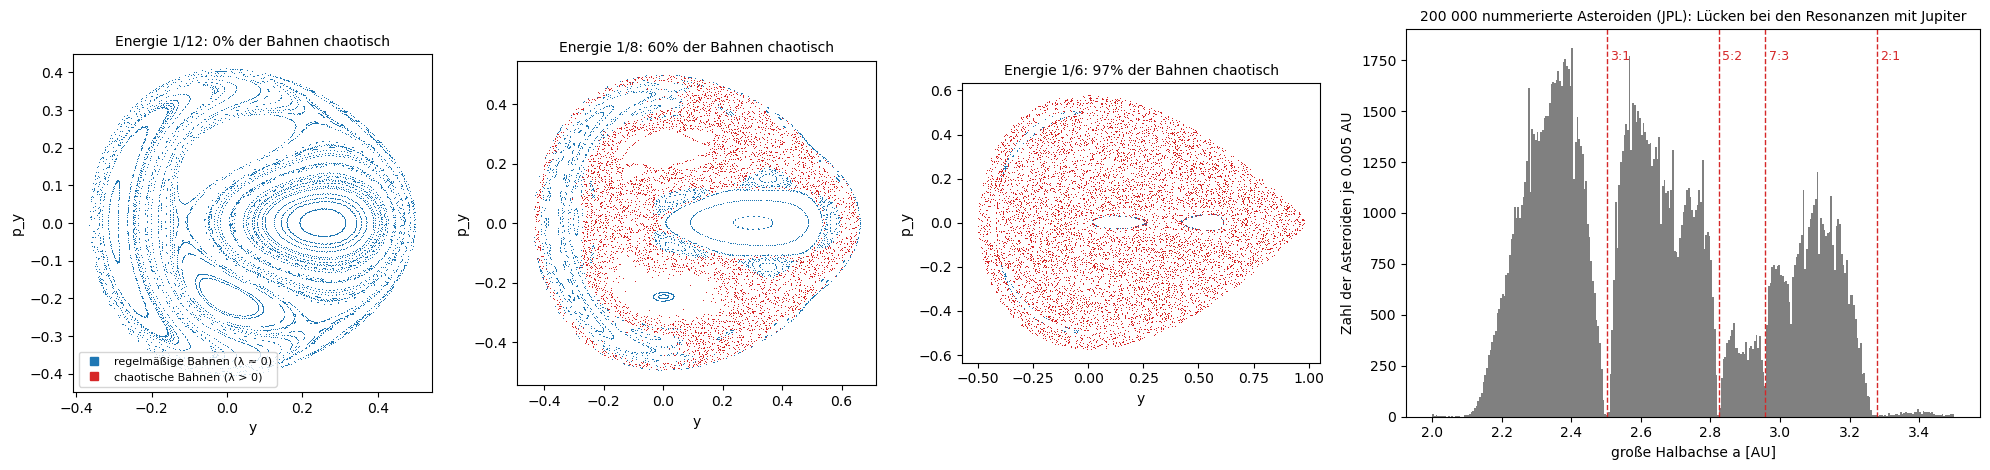

In [3]:
ENERGIES = (1 / 12, 1 / 8, 1 / 6)                  # Energien der Sternbahnen
a_ast = chaos.asteroids(DATA / "jpl")              # 200 000 große Halbachsen, 5 MB beim ersten Lauf
henon = chaos.plot_galaxy_asteroids(a_ast, ENERGIES)

**3. Scrambling: wie schnell ein Quantensystem eine Störung verteilt**

In einem Quantensystem gibt es keine Bahnen und damit keinen Abstand zweier Bahnen. Das Gegenstück fragt, wie schnell eine Störung $W$ am Rand einer Kette auf einen weit entfernten Spin $V$ wirkt: Macht es einen Unterschied, ob man erst $W$ und später $V$ anwendet oder umgekehrt? Das misst der Kommutator $[W(t), V]$, der out-of-time-ordered correlator (OTOC). Gerechnet wird exakt für eine Kette aus 10 Spins, einmal chaotisch (Ising-Kette mit Quer- und Längsfeld) und einmal integrabel (nur Querfeld) (`scrambling.plot_otoc`).

**Begriffe**
- **OTOC:** $C(r, t) = \tfrac12\langle |[W(t), V_r]|^2\rangle$, gemittelt über alle Zustände. $C = 0$: Die Störung hat Platz $r$ noch nicht erreicht; $C = 1$: vollständig verwürfelt.
- **Schmetterlingsgeschwindigkeit $v_B$:** wie schnell die Front von $C$ läuft. In Systemen mit vielen Freiheitsgraden je Platz wächst $C$ zuerst exponentiell mit einem Quanten-Lyapunov-Exponenten; in Ketten aus Spins ½ sieht man vor allem die Front.
- **Integrabel:** Das System hat so viele Erhaltungsgrößen wie Freiheitsgrade (hier ist es äquivalent zu freien Fermionen). Information läuft dann als Teilchen weiter, statt verwürfelt zu werden.

Links breitet sich die Störung vom Rand aus wie in einem Lichtkegel: Platz $r$ ist nach $t \approx 0.3 + 0.6\,(r - 1)$ erreicht ($C > 0.5$), die Schmetterlingsgeschwindigkeit ist also etwa 1.7 Plätze je Zeiteinheit. Hinter der Front bleibt $C$ in der chaotischen Kette hoch, am Platz 5 im Mittel 0.89 für $t > 4.8$; nicht ganz 1, weil 10 Spins wenige sind und die Energie erhalten bleibt. In der integrablen Kette läuft die Front ebenso schnell, aber dahinter fällt $C$ wieder, auf 0.35 im Mittel: Die Information wurde nicht verwürfelt, sondern ist als Teilchen weitergelaufen. Am letzten Platz sind beide hoch, weil dort die Front gerade ankommt und am Rand umkehrt. Chaotisch heißt hier: Eine lokale Störung verteilt sich auf viele Spins und lässt sich lokal nicht mehr zurückholen. Dieses Verwürfeln messen Experimente auf Quantencomputern und mit gefangenen Ionen, und mit derselben Größe fragt man, wie schnell Schwarze Löcher Information verteilen: Für den Quanten-Lyapunov-Exponenten gilt $\lambda \le 2\pi k_BT/\hbar$, und Schwarze Löcher erreichen diese Grenze (Maldacena, Shenker und Stanford 2016).

Ising-Kette mit 10 Spins, h_x = 1.05: Die Störung erreicht Platz r (C > 0.5) nach t = 0.3, 0.9, 1.5, 2.1, 2.7, 3.3, 3.9, 4.5, 5.1; Schmetterlingsgeschwindigkeit v_B ≈ 1.67 Plätze je Zeiteinheit
  chaotisch (h_z = 0.5): C am Platz r = 5 nach t > 4.8 im Mittel 0.89, am letzten Platz 0.73 (vollständig verwürfelt: 1)
  integrabel (h_z = 0): C am Platz r = 5 nach t > 4.8 im Mittel 0.35, am letzten Platz 0.95 (vollständig verwürfelt: 1)


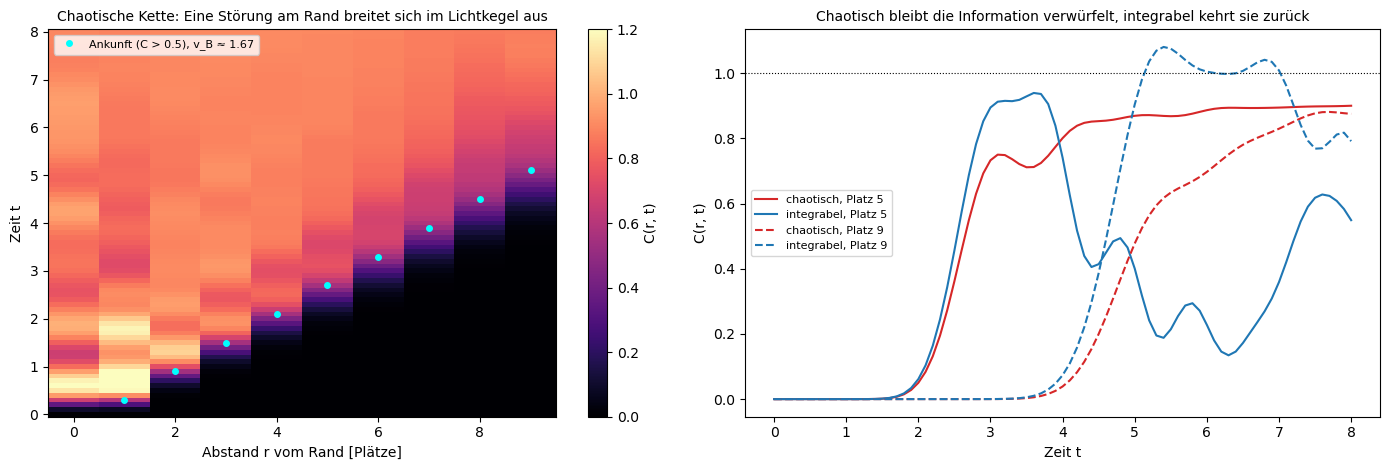

In [4]:
SPINS, HX = 10, 1.05            # Länge der Kette, Querfeld
HZ_CHAOS = 0.5                  # Längsfeld: macht die Kette chaotisch (0 = integrabel)
otoc_chaos, otoc_int = scrambling.plot_otoc(SPINS, HX, HZ_CHAOS)

**4. Vergessen oder erinnern: Thermalisierung und Vielteilchen-Lokalisierung**

Ein abgeschlossenes Quantensystem vergisst normalerweise seinen Anfangszustand: Nach kurzer Zeit sehen alle lokalen Messungen aus wie im thermischen Gleichgewicht (Eigenstate Thermalization Hypothesis). Starke Unordnung kann das verhindern. Eine Kette aus 12 Spins (XXZ-Modell wie in Schritt 2 von `symmetries`) mit zufälligen Feldern der Stärke $W$ startet im Néel-Zustand, in dem jeder zweite Spin oben steht. Die Imbalance misst, wie viel von diesem Muster übrig ist; gemittelt wird über 15 Zufallsfelder je $W$ (`scrambling.mbl`). Dazu die Abstandsstatistik der Energien aus `symmetries`: Abstände wie bei Zufallsmatrizen heißen chaotisch, Poisson-Abstände lokalisiert.

**Begriffe**
- **Imbalance:** $I = \frac1L\sum_i (-1)^i\langle\sigma^z_i\rangle$; 1 im Néel-Zustand, 0 im Gleichgewicht.
- **Vielteilchen-Lokalisierung (MBL):** Die Unordnung erzeugt viele lokale Erhaltungsgrößen, und das System bleibt nahe an seinem Anfang (Basko, Aleiner und Altshuler 2006). Ob das auch in unendlich langen Ketten für immer gilt, ist umstritten (Šuntajs und andere 2020).
- **$W$:** Die Felder $h_i$ sind gleichverteilt in $[-W, W]$; der Übergang liegt für diese Kette bei etwa $W \approx 3.5$ (Pal und Huse 2010).

Links: Bei schwacher Unordnung ($W = 0.5$) fällt die Imbalance bis $t \approx 2$ auf null und bleibt dort (spät 0.06, ein Rest der kurzen Kette): Die Kette vergisst, welche Plätze am Anfang besetzt waren. Bei $W = 10$ bleibt sie bei etwa 0.8, bei $W = 5$ bei 0.55, für alle gerechneten Zeiten bis 1000: Die Kette erinnert sich. Rechts der Übergang: Zwischen $W = 2$ und 4 steigt die späte Imbalance von 0.11 auf 0.48, und im selben Bereich fällt $\langle r\rangle$ von 0.491 auf 0.405, von den Abständen einer Zufallsmatrix (0.529 bei $W = 0.5$) zu Poisson (0.388 bei $W = 8$). Zwei verschiedene Messungen, eine der Dynamik und eine des Spektrums, zeigen denselben Wechsel: Thermalisierung gehört zu chaotischen Spektren, Gedächtnis zu Poisson-Spektren, wie bei der Niveaustatistik in Schritt 2 von `symmetries`. Kalte Atome in optischen Gittern haben genau diese Imbalance gemessen und gesehen, dass sie bei starker Unordnung erhalten bleibt (Schreiber und andere 2015).

Stärke W: Imbalance nach t > 100 | ⟨r⟩ (Poisson 0.386, Zufallsmatrix 0.531)
  W =  0.5:  0.06 | 0.529
  W =  1.0:  0.05 | 0.528
  W =  2.0:  0.11 | 0.491
  W =  3.0:  0.29 | 0.431
  W =  4.0:  0.48 | 0.405
  W =  5.0:  0.55 | 0.398
  W =  6.0:  0.63 | 0.390
  W =  8.0:  0.67 | 0.388
  W = 10.0:  0.79 | 0.393


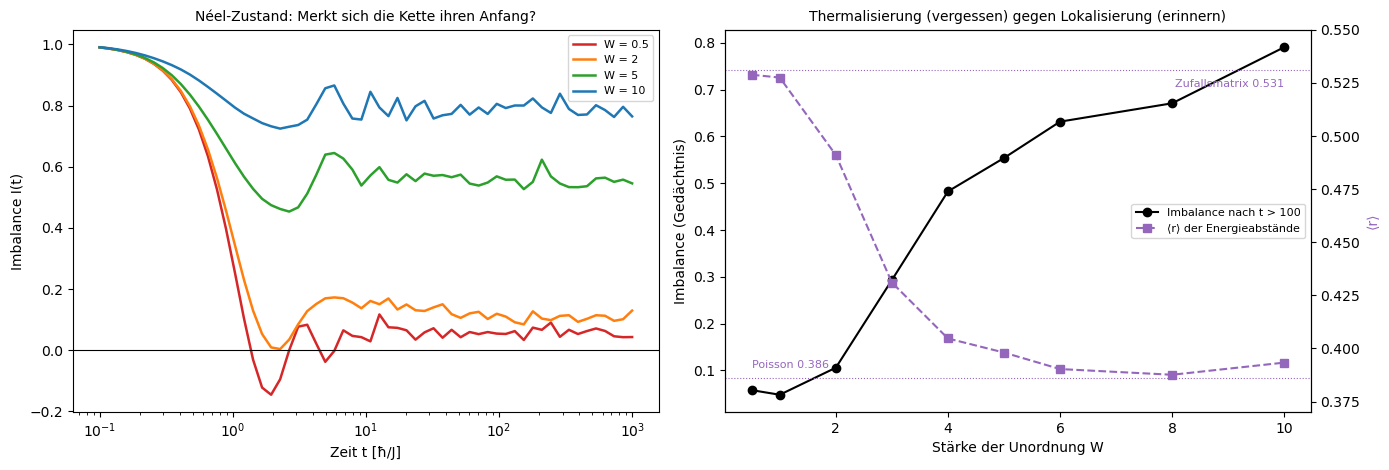

In [5]:
LENGTH = 12                                   # Spins (924 Zustände mit Magnetisierung null)
DISORDER = (0.5, 1, 2, 3, 4, 5, 6, 8, 10)     # Stärken W der Zufallsfelder
times, mbl_runs = scrambling.mbl(LENGTH, DISORDER)
scrambling.plot_mbl(times, mbl_runs)

**5. Synchronisation: ein Phasenübergang als Wechsel der Stabilität**

Glühwürmchen, die im Takt blinken, Schrittmacherzellen im Herzen, Generatoren im Stromnetz: Viele Oszillatoren mit leicht verschiedenen Frequenzen synchronisieren sich, wenn die Kopplung stark genug ist. Das Kuramoto-Modell beschreibt das mit einer Gleichung, $\dot\theta_j = \omega_j + K\,r\,\sin(\psi - \theta_j)$: Jeder Oszillator wird zur mittleren Phase $\psi$ gezogen, umso stärker, je geordneter alle schon sind. Der ungeordnete Zustand ($r = 0$) ist stabil, solange sein Eigenwert $K/2 - \gamma$ negativ ist. Bei $K_c = 2\gamma$ wird er null, und von da an wächst die Ordnung von selbst (`collective.plot_kuramoto`, 2000 Oszillatoren).

**Begriffe**
- **Ordnungsparameter $r$:** die Länge des Mittelwerts der Einheitsvektoren $e^{i\theta_j}$; 0 ohne Ordnung, 1 im Gleichtakt.
- **$\gamma$:** Breite der Verteilung der Eigenfrequenzen (Lorentz-Verteilung), hier 0.5, also $K_c = 1$.
- **Phasenübergang:** Ein Ordnungsparameter wird bei einem kritischen Wert von null verschieden. Genau dort wechselt ein Eigenwert sein Vorzeichen.

Links die Phasen nach $t = 100$: Bei $K = 0.6$ verteilen sie sich über den ganzen Kreis ($r = 0.03$), bei $K = 1.5$ sammelt sich ein Teil ($r = 0.57$), bei $K = 3$ fast alle ($r = 0.82$). Rechts: Unterhalb von $K_c = 1$ bleibt $r$ bei 0.02 bis 0.08, dem Rauschen von 2000 Oszillatoren (etwa $1/\sqrt N = 0.02$). Darüber folgt die Simulation der Theorie auf 0.002: 0.575 gegen 0.577 bei $K = 1.5$, 0.864 gegen 0.866 bei $K = 4$. Der Übergang ist scharf, weil der Eigenwert $K/2 - \gamma$ genau bei $K_c$ sein Vorzeichen wechselt: Darunter klingt jede zufällige Ordnung ab, darüber wächst sie, bis die Nichtlinearität sie begrenzt. Dasselbe Muster, ein Eigenwert wird null und ein Ordnungsparameter wächst wie $\sqrt{K - K_c}$, zeigen Magnete am Curie-Punkt (in der einfachsten Näherung) und Laser an ihrer Schwelle.

Kuramoto, 2000 Oszillatoren, Lorentz-Frequenzen mit γ = 0.5: kritische Kopplung K_c = 2γ = 1.0
  K = 0.5: Eigenwert des ungeordneten Zustands K/2 − γ = -0.25; r gemessen 0.029, Theorie 0.000
  K = 1.0: Eigenwert des ungeordneten Zustands K/2 − γ = +0.00; r gemessen 0.080, Theorie 0.000
  K = 1.5: Eigenwert des ungeordneten Zustands K/2 − γ = +0.25; r gemessen 0.575, Theorie 0.577
  K = 2.0: Eigenwert des ungeordneten Zustands K/2 − γ = +0.50; r gemessen 0.705, Theorie 0.707
  K = 3.0: Eigenwert des ungeordneten Zustands K/2 − γ = +1.00; r gemessen 0.815, Theorie 0.816
  K = 4.0: Eigenwert des ungeordneten Zustands K/2 − γ = +1.50; r gemessen 0.864, Theorie 0.866


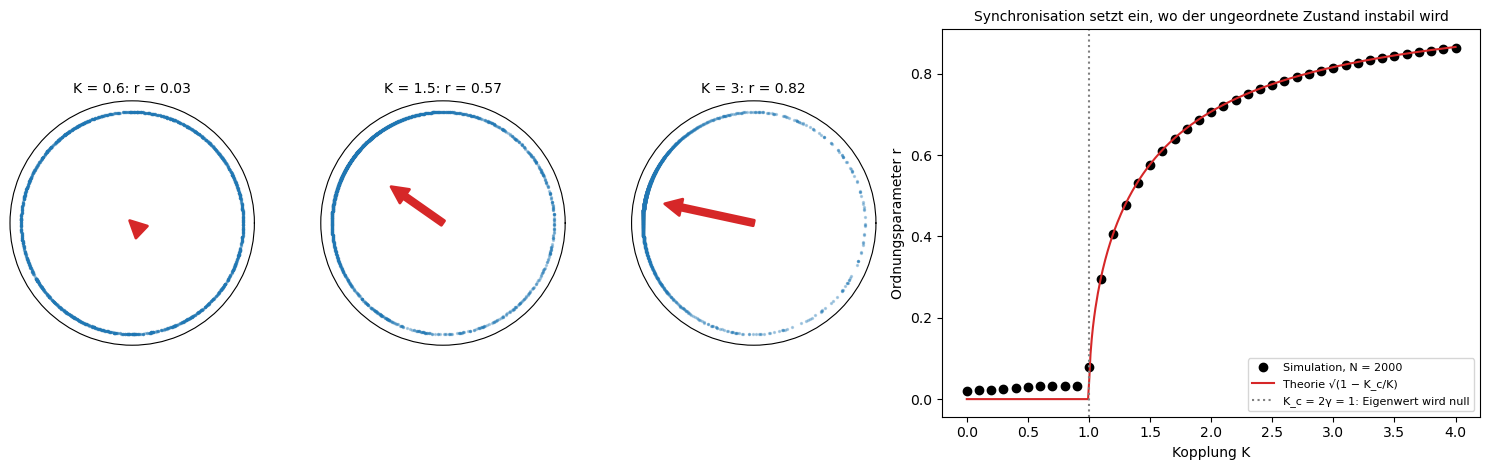

In [6]:
OSCILLATORS, GAMMA = 2000, 0.5         # Zahl der Oszillatoren, Breite der Frequenzverteilung
sync = collective.plot_kuramoto(OSCILLATORS, GAMMA)

**6. Das Gedächtnis des Universums: wie viel Helium es gibt**

In der ersten Sekunde nach dem Urknall wandelten schwache Reaktionen Neutronen und Protonen ständig ineinander um. Eine Abweichung vom Gleichgewicht klang mit der Rate $\Gamma$ ab, während sich das Universum mit der Rate $H$ ausdehnte. Solange $\Gamma > H$, vergaß das Universum jede Abweichung. Als $\Gamma$ unter $H$ fiel, fror der Neutronenanteil ein und sank danach nur noch durch den Zerfall der Neutronen. Fast alle übrigen Neutronen landeten Minuten später in Helium-4. Gerechnet wird mit den Phasenraum-Integralen der schwachen Reaktionen und der Temperaturgeschichte mit dem Aufheizen der Photonen, als Elektronen und Positronen zerstrahlten (`freezeout.plot_freezeout`). Verglichen wird mit dem Heliumanteil, den man in sauerstoffarmen Galaxien beobachtet.

**Begriffe**
- **$\Gamma = \lambda_{np} + \lambda_{pn}$:** die Rate, mit der eine Abweichung vom Gleichgewicht abklingt, also der Betrag des Eigenwerts der linearisierten Gleichung.
- **Ausfrieren:** $\Gamma$ fällt unter $H$; ab dann bleibt die Abweichung vom Gleichgewicht stehen.
- **$Y_p$:** Massenanteil von Helium-4 aus dem Urknall. Jeder Heliumkern enthält zwei Neutronen und zwei Protonen, deshalb ist $Y_p \approx 2X_n$ mit dem Neutronenanteil $X_n$.

Links: Bei 3 MeV ist $\Gamma$ 74-mal größer als $H$, und der Neutronenanteil folgt dem Gleichgewicht (0.396 gegen 0.394). Bei 0.66 MeV, 1.7 s nach dem Urknall, fällt $\Gamma$ unter $H$. Bei 0.5 MeV ist $\Gamma/H$ nur noch 0.48; im Gleichgewicht wären es 0.070 Neutronen, tatsächlich bleiben 0.190: Das Universum erinnert sich an einen früheren Zustand. Danach sinkt der Anteil langsamer, erst durch die letzten Reaktionen, dann durch den Zerfall der Neutronen (Lebensdauer 878 s). Rechts: Helium entsteht, sobald Deuterium nicht mehr sofort von Photonen zerschlagen wird. Die einfache Saha-Bedingung setzt das bei 0.066 MeV an und gibt $Y_p = 0.229$. In einer vollständigen Rechnung mit allen Kernreaktionen entsteht die Hälfte des Heliums schon bei 0.072 MeV (250 s), weil ein kleiner Anteil Deuterium genügt, damit schnelle Kernreaktionen die Neutronen zu Helium weiterreichen. Dort ergibt sich $Y_p = 0.242$, wie in der vollständigen Rechnung mit denselben Näherungen (0.2425); kleine Korrekturen an den Raten heben es auf 0.247 (PRIMAT), beobachtet sind 0.2453 ± 0.0034. Ohne das Ausfrieren gäbe es praktisch kein Helium ($3\cdot10^{-8}$): Fast ein Viertel der Masse der gewöhnlichen Materie ist ein eingefrorenes Gedächtnis an die erste Sekunde.

Ausfrieren (Γ = λ_np + λ_pn fällt unter H): T = 0.66 MeV, t = 1.71 s; Neutronenanteil 0.212, im Gleichgewicht wären es 0.125
  T = 3.01 MeV: Γ/H =    74.30, X_n = 0.396, Gleichgewicht 0.394
  T = 1.00 MeV: Γ/H =     2.99, X_n = 0.256, Gleichgewicht 0.215
  T = 0.50 MeV: Γ/H =     0.48, X_n = 0.190, Gleichgewicht 0.070
Helium entsteht (fast alle Neutronen enden in Helium-4, also Y_p = 2 X_n):
  grob nach Saha (X_d = X_n X_p) bei T = 0.066 MeV, t = 296 s: X_n = 0.115, Y_p = 0.229
  wie im vollständigen Netzwerk bei T = 0.072 MeV, t = 250 s: X_n = 0.1208, Y_p = 0.242
  zum Vergleich: PRIMAT 0.2472, Beobachtung 0.2453 ± 0.0034; ohne Ausfrieren (immer im Gleichgewicht) wären es 3e-08


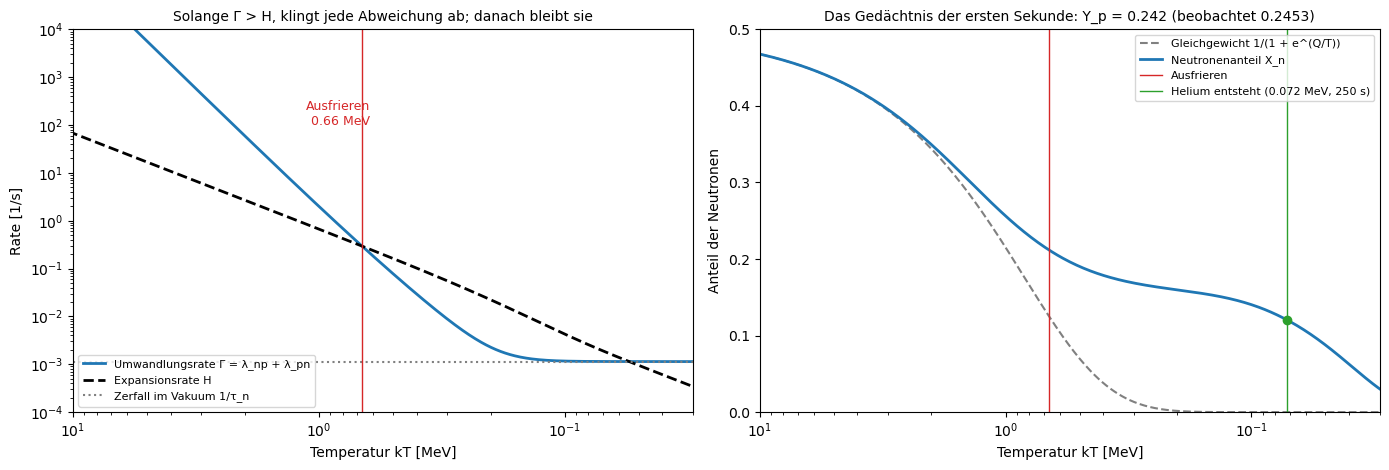

In [7]:
yp = freezeout.plot_freezeout()      # Temperaturgeschichte von 30 bis 0.01 MeV, wenige Sekunden

**7. Rückkopplung: adaptive Optik und Lernrate**

Rückkopplung verschiebt Eigenwerte. Ein Regelkreis misst eine Abweichung und korrigiert sie; je stärker er korrigiert, desto schneller klingt sie ab, bis er überkorrigiert und schwingt. Links eine Mode der adaptiven Optik eines Teleskops: Die Atmosphäre verschiebt die Phase des Lichts (Turbulenz mit Kolmogorov-Spektrum, 1000 Bilder pro Sekunde), ein verformbarer Spiegel gleicht sie aus, aber die Messung wirkt erst zwei Bilder später (`feedback.ao_loop`). Rechts der Gradientenabstieg, das Arbeitspferd des maschinellen Lernens, an echten Daten: lineare Regression auf dem Diabetes-Datensatz (442 Patienten, 10 Merkmale). Beide Male entscheidet dieselbe Rechnung: Ein Schritt multipliziert die Abweichung mit einem Faktor, und dessen Betrag muss kleiner als 1 sein (`feedback.plot_feedback`).

**Begriffe**
- **Verstärkung $g$:** welcher Anteil der gemessenen Abweichung je Bild korrigiert wird.
- **Stabilitätsgrenze:** Die Nullstellen von $z^2 - z + g$ (zwei Bilder Verzögerung) müssen im Einheitskreis liegen; das gilt für $g < 1$.
- **Lernrate $\eta$:** Längs einer Hauptachse der Hesse-Matrix mit Krümmung $\lambda$ multipliziert ein Schritt den Fehler mit $1 - \eta\lambda$. Stabil ist das für $\eta < 2/\lambda_{\max}$, mit dem größten Eigenwert, der ersten Hauptachse wie in `principal_axes`.

Links: Mit $g = 0.02$ korrigiert der Spiegel zu langsam, der Rest ist 0.89 der Turbulenz. Mit wachsender Verstärkung folgt er besser, am besten bei $g = 0.48$ mit 0.31. Darüber verstärkt der Kreis wegen der Verzögerung das Messrauschen, der Rest steigt wieder, an der Grenze $g = 1$ auf 30, und darüber wächst er ohne Grenze. Die beste Verstärkung liegt also deutlich unter der Grenze; in der Praxis hält man diesen Abstand bewusst ein (Stabilitätsreserve). Rechts der Gradientenabstieg: Die Hesse-Matrix hat Eigenwerte von 0.009 bis 4.02, die Grenze ist also $2/\lambda_{\max} = 0.497$. Mit der halben Grenze und mit 95 % davon erreicht der Verlust nach 200 Schritten 0.242, fast das Minimum der kleinsten Quadrate (0.241); mit 5 % über der Grenze wächst er auf $5\cdot10^{15}$. Die steilste Richtung bestimmt, wie groß ein Schritt sein darf, die flachste (0.009), wie lange es dauert; ihr Verhältnis von etwa 450 ist die Konditionszahl. Neuronale Netze trainieren oft genau an dieser Grenze: Ihre größte Krümmung wächst im Training, bis sie bei etwa $2/\eta$ stehen bleibt (Edge of Stability, Cohen und andere 2021).

Adaptive Optik, 2 Bilder Verzögerung: stabil bis g = 1.000 (Nullstellen von z² − z + g); Rest (ohne Regelung 1) bei g = 0.02: 0.89, am besten 0.31 bei g = 0.48, bei g = 1.00: 29.59; darüber wächst er ohne Grenze (5 von 55 Verstärkungen)
Diabetes-Daten (442 Patienten, 10 Merkmale): Eigenwerte der Hesse-Matrix von 0.009 bis 4.02; Grenze der Lernrate 2/λ_max = 0.497
  Lernrate 0.50·2/λ_max: Verlust nach 200 Schritten 0.242
  Lernrate 0.95·2/λ_max: Verlust nach 200 Schritten 0.242
  Lernrate 1.05·2/λ_max: Verlust nach 200 Schritten 4.6e+15


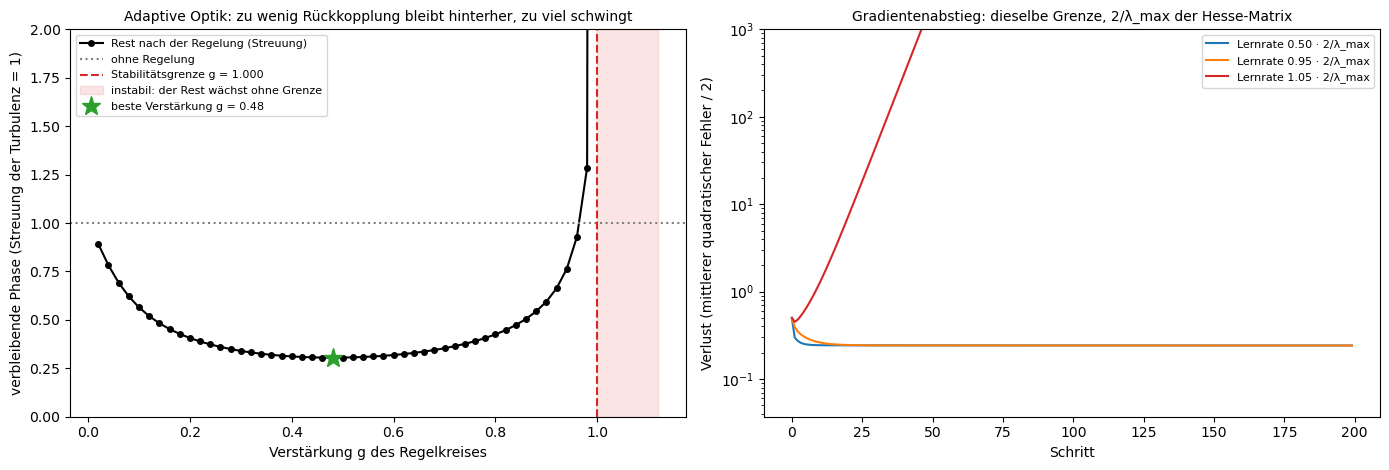

In [8]:
GAINS = np.linspace(0.02, 1.1, 55)        # Verstärkungen des Regelkreises
RATES = (0.5, 0.95, 1.05)                 # Lernraten in Einheiten von 2/λ_max
g_max, eta_max = feedback.plot_feedback(GAINS, factors=RATES)

**8. Optimal Control: eine Raumsonde am instabilen Punkt L2 halten**

Rückkopplung kann eine Instabilität auch beseitigen. Das James-Webb-Teleskop kreist 1.5 Millionen km hinter der Erde um den Lagrange-Punkt L2. Dort halten sich die Anziehung von Sonne und Erde und die Fliehkraft der gemeinsamen Drehung die Waage, aber das Gleichgewicht ist instabil wie ein Bleistift auf der Spitze: Eine kleine Abweichung wächst exponentiell, und die Sonde muss alle paar Wochen ihre Triebwerke zünden. Gerechnet wird die linearisierte Bewegung in der Ebene der Erdbahn (eingeschränktes Dreikörperproblem, Schritte von einem Tag, Start mit 100 km Abweichung). Optimal Control fragt nicht nur, ob ein Regler die Abweichung dämpft, sondern welcher es am günstigsten tut. Der lineare quadratische Regler (LQR) minimiert $J = \sum_k \big(|\mathbf r_k|^2 + R\,|\mathbf u_k|^2\big)$, die Abweichung $\mathbf r$ plus den mit $R$ gewichteten Schub $\mathbf u$ (`control.lqr`). Rechts lernt ein Agent denselben Regler ohne Modell, nur durch Ausprobieren im Simulator (Q-Learning, `control.q_learning`); er startet mit einem stabilen, aber schlechten Regler von Hand (`control.plot_control`).

**Begriffe**
- **Lagrange-Punkt L2:** einer von fünf Punkten, an denen ein kleiner Körper mit Sonne und Erde mitläuft, ohne dass sich die Abstände ändern. L2 liegt auf der Linie Sonne–Erde jenseits der Erde; Sonne, Erde und Mond stehen von dort aus auf derselben Seite, und ein Schild hält ihr Licht vom Teleskop fern.
- **Riccati-Gleichung:** Für ein lineares System mit quadratischen Kosten sind auch die Kosten ab einem Zustand quadratisch, $\mathbf x^\top P\,\mathbf x$. Die Bellman-Gleichung (Kosten jetzt plus Kosten ab dem nächsten Zustand, bestmöglich gewählt) wird dann zu einer Gleichung für die Matrix $P$, und daraus folgt der Regler $\mathbf u = -K\mathbf x$.
- **Q-Learning:** $Q(\mathbf x, \mathbf u)$ sind die Kosten, wenn man jetzt den Schub $\mathbf u$ gibt und danach dem Regler folgt. Der Agent schätzt $Q$ aus 100 Übergängen des Simulators je Iteration und nimmt dann den Schub, der $Q$ am kleinsten macht. Das ist Reinforcement Learning; hier führt es genau zur Lösung der Riccati-Gleichung.

Links: Ohne Steuerung wächst die Abweichung alle 23.4 Tage um den Faktor e und verdoppelt sich in 16 Tagen. Zwischen zwei Manövern im Abstand von 42 Tagen, wie sie das Teleskop im Betrieb meist fährt (geplant waren 21), wird sie also sechsmal größer. Die linearisierte Bewegung hat die Eigenwerte ±0.0427 und ±0.0354i je Tag: Eine Richtung wächst, eine schrumpft, und dazu kommt eine Schwingung mit der Periode 178 Tage. Auf solchen Schwingungen kreist das Teleskop um L2, ein Umlauf dauert etwa ein halbes Jahr. Der sparsame Regler ($R = 10\,000$) dreht fast nur das Vorzeichen des wachsenden Eigenwerts um (+0.0427 → −0.0436 je Tag) und dämpft die Schwingung kaum (−0.0153): Er bekämpft nur, was wächst, und kommt mit 13.3 cm/s aus; nach einem Jahr sind 0.3 km übrig. Der schnelle Regler ($R = 1$) dämpft alles mit 0.21 je Tag, braucht aber 33.0 cm/s und in der Spitze 16-mal so viel Schub. Der Regler von Hand, eine Feder mit Dämpfer in jeder Richtung, ist stabil, aber langsam und teuer: 47.3 cm/s, und nach einem Jahr sind noch 12 km übrig. Rechts: Jeder Punkt der schwarzen Kurve ist für sein $R$ der beste mögliche Regler; weniger Abweichung gibt es nur für mehr Schub. Der Regler von Hand liegt weit darüber: Mit demselben mittleren Schub (1.53 mm/s je Tag) bleibt er im Mittel 49 km entfernt, der LQR 17 km. Der Agent kennt nur den Simulator und liegt trotzdem nach der ersten Iteration fast auf der Front (1 % darüber); danach rückt er zum Punkt für $R = 100$ vor. Sein Abstand zum Regler aus der Riccati-Gleichung fällt von 1 über 0.7, 0.2, 0.03 und 0.001 auf $9\cdot10^{-7}$ und $7\cdot10^{-13}$: Ab der dritten Iteration verdoppelt sich die Zahl der richtigen Stellen, denn diese Politik-Iteration ist das Newton-Verfahren für die Riccati-Gleichung (Hewer 1971). Sie braucht allerdings einen stabilen Start: Mit einem instabilen Regler sind die Kosten unendlich, und es gibt nichts zu lernen. Für Reinforcement Learning an echten Systemen heißt das: erst sicher, dann optimal.

L2 liegt 1.51 Mio km hinter der Erde. Eigenwerte der linearisierten Bewegung: ±0.0427 und ±0.0354i je Tag
  Ohne Steuerung wächst eine Abweichung alle 23.4 Tage um den Faktor e (verdoppelt sich in 16.2 Tagen); die Schwingung hat die Periode 178 Tage.
Optimale Regler (LQR) für eine Abweichung von 100 km, ein Jahr lang; Raten = Logarithmus der Eigenwerte im geschlossenen Kreis je Tag (alle negativ: stabil):
  R = 10000: Δv = 13.3 cm/s, mittlere Abweichung 28.7 km, mittlerer Schub 0.97 mm/s je Tag; Raten -0.0436, -0.0153
  R = 1: Δv = 33.0 cm/s, mittlere Abweichung 10.7 km, mittlerer Schub 5.88 mm/s je Tag; Raten -0.2085, -0.2079
  Regler von Hand: Δv = 47.3 cm/s, mittlere Abweichung 49.3 km, mittlerer Schub 1.53 mm/s je Tag
Q-Learning ohne Modell (R = 100, 100 Übergänge je Iteration), relativer Abstand zum Regler aus der Riccati-Gleichung: 1e+00, 7e-01, 2e-01, 3e-02, 1e-03, 9e-07, 7e-13, 4e-14, 4e-14


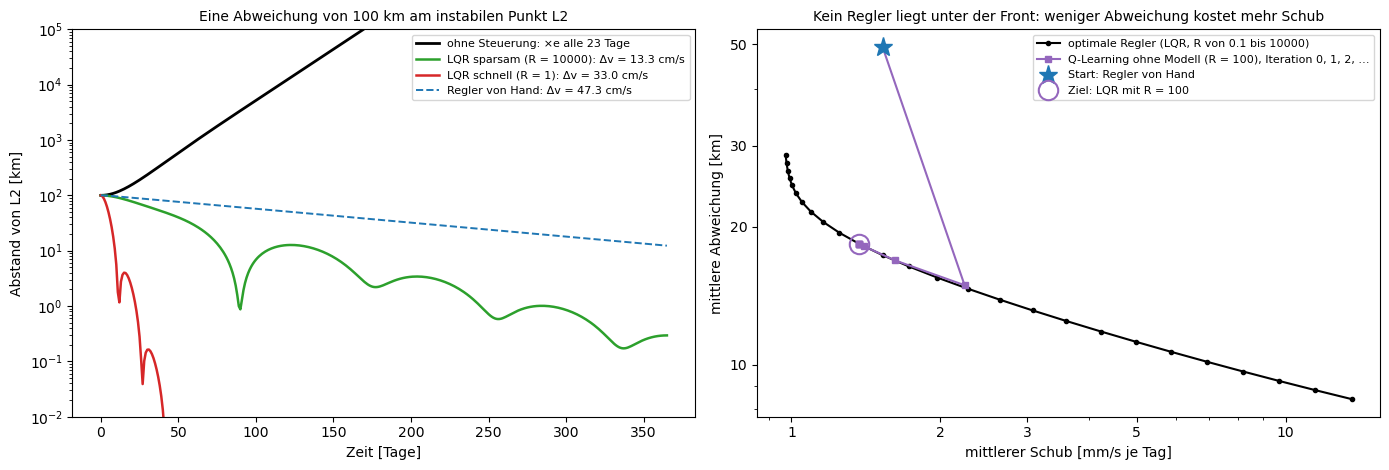

In [9]:
WEIGHTS = (1e4, 1.0)            # R: Schub teuer (sparsam) und Schub billig (schnell)
R_LEARN = 100.0                  # R für den Agenten
K_opt, K_learned = control.plot_control(show=WEIGHTS, R_learn=R_LEARN)

**9. Ausblick: Qubits steuern und korrigieren**

Auch Quantengatter werden optimal gesteuert. Ein Gatter ist ein kurzer Mikrowellenpuls, und GRAPE (Khaneja und andere 2005) formt ihn wie der LQR in Schritt 8 als Minimum einer Kostenfunktion, hier mit Gradienten: Das Gatter soll stimmen, der Puls kurz sein, und ein supraleitendes Qubit soll nicht in sein drittes Niveau springen (der DRAG-Puls, Motzoi und andere 2009, löst genau das). Steuern allein reicht aber nicht, denn in einem Quantencomputer klingt eine Störung nicht von selbst ab: Nichts dämpft einen Fehler auf einem Qubit, er bleibt und häuft sich mit jedem Gatter. Quantenfehlerkorrektur baut deshalb einen Regelkreis ein. Hilfsqubits messen ständig Paritäten benachbarter Qubits (Syndrome), ein klassischer Decoder schließt daraus auf den Fehler, und die Korrektur folgt. Ob das hilft, ist wieder eine Frage der Stabilität: Liegt die Fehlerrate der einzelnen Qubits unter einer Schwelle, wird der Fehler des geschützten Qubits mit jedem größeren Code um einen Faktor Λ > 1 kleiner; darüber wächst er. Google hat 2024 gezeigt, dass ein Oberflächencode unter dieser Schwelle arbeitet, mit Λ = 2.14 je Schritt in der Größe des Codes.

Als Code wären die nächsten Schritte ein GRAPE-Puls für ein Qubit mit drei Niveaus und ein Wiederholungscode mit Rauschen, erst simuliert, dann auf echter Hardware. Dieselbe Frage stellt sich bei KI-Agenten, die ihre eigenen Ergebnisse prüfen und nachbessern: Eine Schleife aus Erzeugen, Bewerten und Korrigieren ist ein Regelkreis, und ob sie zu einem guten Ergebnis konvergiert oder sich aufschaukelt, hängt davon ab, ob jede Runde im Mittel mehr Fehler beseitigt, als sie hinzufügt (eigene Überlegung, nicht gemessen).